In [1]:
# Import the libraries you need for this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint, uniform, loguniform

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

In [9]:
# load the file
df = pd.read_csv("data/bike_sharing.csv", parse_dates=["datetime"])

In [10]:
df.head(5)

,datetime,casual,member,rentals,temperature,feels_like,humidity,precipitation,snowfall,wind_speed,cloud_cover,weather_code,holiday
0,2024-10-01 00:00:00,47,89,136,18.1,19.5,96,0.2,0.0,8.6,100,51,NaN
1,2024-10-01 01:00:00,18,30,48,18.2,19.6,96,0.1,0.0,8.9,100,51,NaN
2,2024-10-01 02:00:00,14,17,31,18.2,19.2,94,0.0,0.0,10.3,100,3,NaN
3,2024-10-01 03:00:00,6,9,15,17.9,18.6,93,0.0,0.0,11.7,100,3,NaN
4,2024-10-01 04:00:00,7,20,27,17.6,18.1,93,0.1,0.0,12.4,100,51,NaN


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   datetime       17520 non-null  datetime64[us]
 1   casual         17520 non-null  int64         
 2   member         17520 non-null  int64         
 3   rentals        17520 non-null  int64         
 4   temperature    17520 non-null  float64       
 5   feels_like     17520 non-null  float64       
 6   humidity       17520 non-null  int64         
 7   precipitation  17520 non-null  float64       
 8   snowfall       17520 non-null  float64       
 9   wind_speed     17520 non-null  float64       
 10  cloud_cover    17520 non-null  int64         
 11  weather_code   17520 non-null  int64         
 12  holiday        576 non-null    str           
dtypes: datetime64[us](1), float64(5), int64(6), str(1)
memory usage: 1.7 MB


In [16]:
# target = 'rentals'
df['weather_code'].value_counts() - df['weather_code'].isna().value_counts()

weather_code
0    -11656.0
1         NaN
2         NaN
3         NaN
51        NaN
53        NaN
55        NaN
61        NaN
63        NaN
65        NaN
71        NaN
73        NaN
75        NaN
Name: count, dtype: float64

In [53]:
df.isna().sum()

datetime             0
casual               0
member               0
rentals              0
temperature          0
feels_like           0
humidity             0
precipitation        0
snowfall             0
wind_speed           0
cloud_cover          0
weather_code         0
holiday          16944
dtype: int64

In [54]:
df['holiday'].unique()

<StringArray>
[                                   nan,
                         'Columbus Day',
                         'Veterans Day',
                     'Thanksgiving Day',
                        'Christmas Day',
                       'New Year's Day',
  'Birthday of Martin Luther King, Jr.',
                'Washington's Birthday',
                  'DC Emancipation Day',
                         'Memorial Day',
 'Juneteenth National Independence Day',
                     'Independence Day',
                            'Labor Day']
Length: 13, dtype: str

In [23]:
df['weather_code'].unique()

array([51,  3, 53, 61,  2,  0,  1, 63, 55, 71, 73, 75, 65])

In [22]:
df['weather_code'].nunique()

13

In [ ]:
# Drop weather code since it adds no value
df.groupby("weather_code")[["precipitation", "snowfall", "cloud_cover"]].agg(["min", "max"])

precipitation       snowfall       cloud_cover     
                       min   max      min   max         min  max
weather_code                                                    
0                      0.0   0.0     0.00  0.00           0   19
1                      0.0   0.0     0.00  0.00          20   49
2                      0.0   0.0     0.00  0.00          50   79
3                      0.0   0.0     0.00  0.00          80  100
51                     0.1   0.4     0.00  0.00           2  100
53                     0.5   0.9     0.00  0.00           3  100
55                     1.0   1.2     0.00  0.00           8  100
61                     1.3   2.4     0.00  0.00          32  100
63                     2.5   7.5     0.00  0.00          28  100
65                     7.7  13.6     0.00  0.00          84  100
71                     0.1   3.5     0.07  0.14          25  100
73                     0.3   2.8     0.21  0.77          95  100
75                     1.2   2.9     0.84  2.03         100  100

In [32]:
# first split
df_train, df_test = train_test_split(
    df, test_size=0.2, random_state=42
)


In [ ]:
target = 'rentals'
df_sample = df_train.drop(columns=target)
df_target = df[target]

# Data correlation

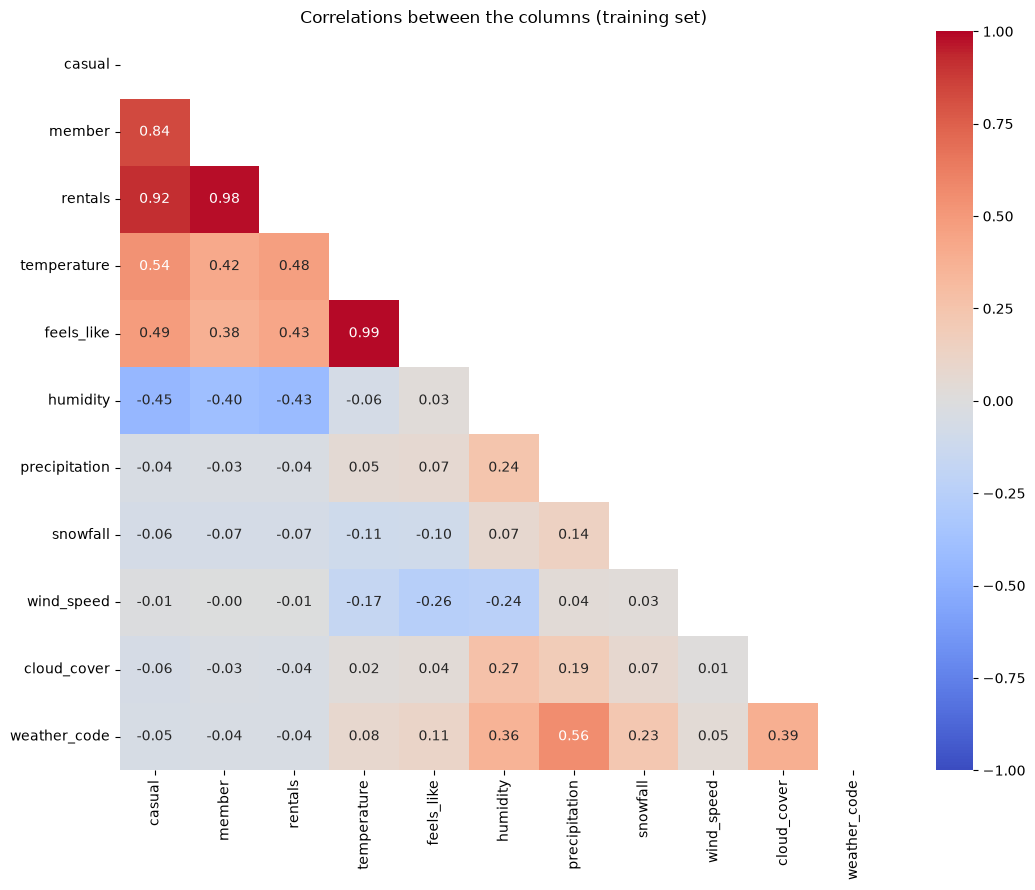

In [ ]:

numeric = df_train.select_dtypes("number")
corr = numeric.corr()

# True for the upper triangle and the diagonal -> those cells get hidden
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlations between the columns (training set)")
plt.tight_layout()
plt.show()

We drop 'feels like'

<Axes: xlabel='rentals', ylabel='Count'>

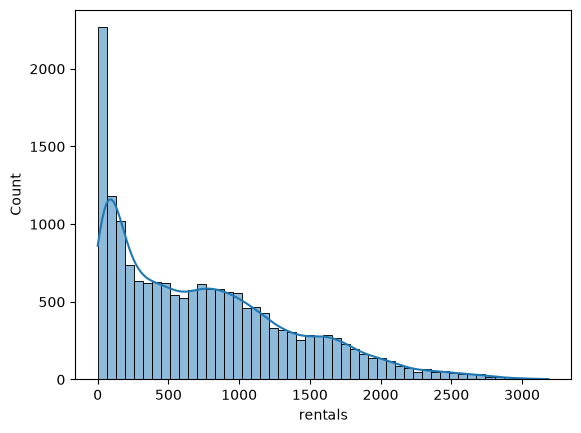

In [44]:
sns.histplot(data=df, x=target, bins=50, kde=True)

In [42]:
df[target].skew()

np.float64(0.8480867931421762)

In [45]:
df[df["datetime"].dt.strftime("%Y-%m-%d") == "2025-03-09"][["datetime", "rentals"]].head(6)

,datetime,rentals
3816,2025-03-09 00:00:00,309
3817,2025-03-09 01:00:00,214
3818,2025-03-09 02:00:00,0
3819,2025-03-09 03:00:00,155
3820,2025-03-09 04:00:00,61
3821,2025-03-09 05:00:00,54


In [49]:
df[df["rentals"] == 0]



,datetime,casual,member,rentals,temperature,feels_like,humidity,precipitation,snowfall,wind_speed,cloud_cover,weather_code,holiday
3818,2025-03-09 02:00:00,0,0,0,1.0,-3.2,59,0.0,0.0,8.2,0,0,NaN
12554,2026-03-08 02:00:00,0,0,0,14.2,13.8,88,0.0,0.0,7.5,73,2,NaN


In [51]:
df_train.describe().T

,count,mean,min,25%,50%,75%,max,std
datetime,14016,2025-10-01 05:16:10.119863,2024-10-01 00:00:00,2025-04-01 09:45:00,2025-10-01 01:30:00,2026-04-02 05:15:00,2026-09-30 23:00:00,NaN
casual,14016.0,218.758134,0.0,47.0,158.0,320.0,1593.0,211.07215
member,14016.0,534.566781,0.0,134.0,464.0,813.0,2465.0,449.294812
rentals,14016.0,753.324914,0.0,186.75,639.0,1142.0,3188.0,636.260286
temperature,14016.0,14.102775,-15.0,5.8,15.3,22.7,39.7,10.512618
feels_like,14016.0,12.917559,-19.7,2.3,13.5,24.1,43.9,13.20581
humidity,14016.0,67.78232,15.0,53.0,68.0,84.0,100.0,19.018021
precipitation,14016.0,0.136173,0.0,0.0,0.0,0.0,13.6,0.643516
snowfall,14016.0,0.00442,0.0,0.0,0.0,0.0,2.03,0.064462
wind_speed,14016.0,10.127811,0.0,6.0,9.0,13.3,39.7,5.60369


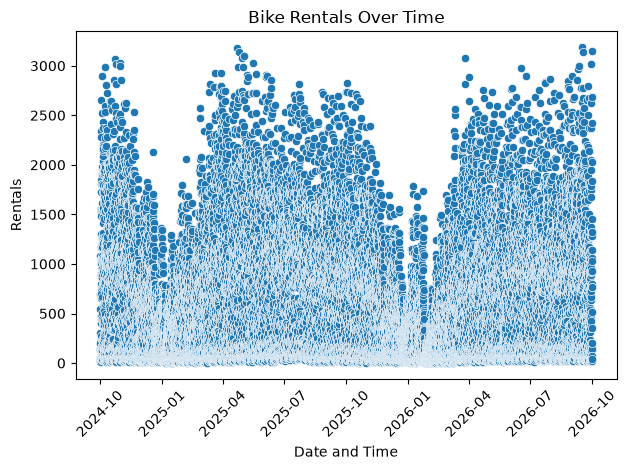

In [52]:
sns.scatterplot(data=df, x="datetime", y=target)

plt.title("Bike Rentals Over Time")
plt.xlabel("Date and Time")
plt.ylabel("Rentals")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Features to be dropped:  
1- waether_code: other features carry the same information  
2- feels_like: almost one to one with temperature  
3- casual & memeber : the same number of target -total rentals-  
**holiday: needs to be binary and nan treated as 0 otherwise 1, also make sure its dtype is not a string anymore  
** use the log1p for the target  
** Transform datetime into features:
	hour  
	day_of_week. 
	is_weekend. 
	season:	Winter, spring, summer, autumn  
** remove days where rental is 0
